In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

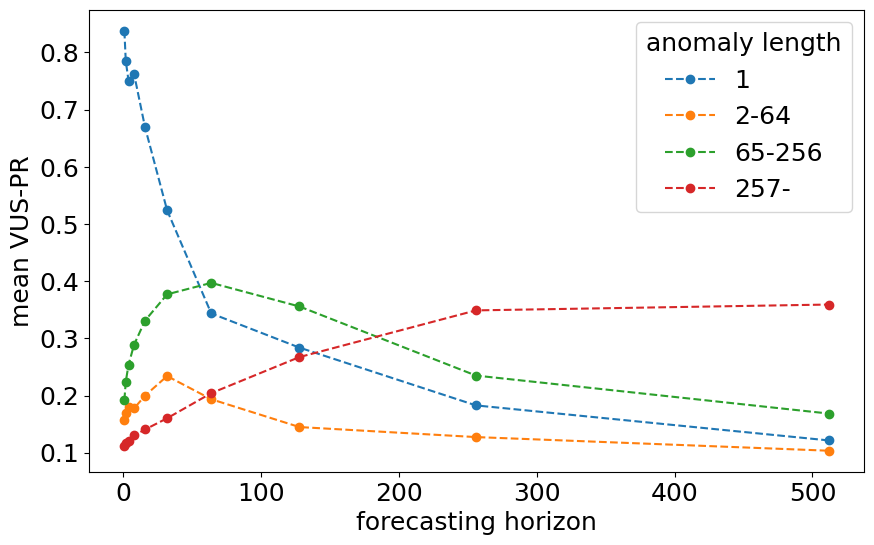

In [7]:
data_direc = '../results/tsfms/horizons/bolt_small_long_horizon_512'

# Other options for data_direc:
# data_direc = '../results/tsfms/horizons/bolt_base_long_horizon_512'
# data_direc = '../results/tsfms/horizons/timesfm-1.0-200m_long_horizon_512'
# data_direc = '../results/tsfms/horizons/timesfm-2.0-500m_long_horizon_512'

horizons = 2 ** np.arange(10)

# Read results for different horizons and merge them into a single dataframe

df = pd.DataFrame()

for horizon in horizons:
    results_file = f'{data_direc}_{horizon}.csv'
    if not os.path.isfile(results_file):
        print(f'No such file: {results_file}')
        continue
    results = pd.read_csv(results_file)
    df[f'{horizon}'] = results['VUS-PR'].values

# Read anomaly length information from the results of the Elephant paper and merge it with the current dataframe
elephant_results = pd.read_csv('./uni_mergedTable_VUS-PR.csv')
df = pd.concat([df, elephant_results.iloc[:, -7:]], axis=1)

# Define intervals for anomaly length
intervals = [1, 64, 256]

# Visualize the results for different anomaly lengths and forecasting horizons

plt.figure(figsize=(10, 6))
font_size = 18
plt.rcParams.update({'font.size': font_size})

results = df[(df['point_anomaly'] == 1) & (df['seq_anomaly'] == 0)].iloc[:, :10].mean().values
plt.plot(2**np.arange(10), results, '--o', label='1')

for i in range(len(intervals)-1):

    lower_bound = intervals[i]
    upper_bound = intervals[i+1]

    results = df[(df['point_anomaly'] == 0) & (df['num_anomaly'] == 1) & (df['avg_anomaly_len'] > lower_bound) & (df['avg_anomaly_len'] <= upper_bound)].iloc[:, :10].mean().values

    plt.plot(2**np.arange(10), results, '--o', label=f'{lower_bound+1}-{upper_bound}')

results = df[(df['point_anomaly'] == 0) & (df['num_anomaly'] == 1) & (df['avg_anomaly_len'] > 512)].iloc[:, :10].mean().values
plt.plot(2**np.arange(10), results, '--o', label=f'{intervals[-1]+1}-')

plt.legend(title='anomaly length')
plt.xlabel('forecasting horizon')
plt.ylabel('mean VUS-PR')
plt.show()